# 01. Eksplorasi data (EDA)

Tahap 2 di PLAN.md.

Data: `data/processed/desa_clean.parquet`, hasil `src/build_dataset.py` dari kode wilayah Kepmendagri No 300.2.2-2138 Tahun 2025.

Yang dilihat:

1. Jumlah desa per provinsi dan per wilayah besar
2. Panjang nama desa
3. Nama desa paling sering dan nama kembar lintas provinsi
4. Kata pertama dan akhiran yang paling umum per wilayah

Grafik disimpan di `reports/figures/01_*.png`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.regions import WILAYAH

FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# palet kategori (dataviz, sudah divalidasi untuk buta warna), urutan tetap per wilayah
URUT = list(WILAYAH.keys())
WARNA = dict(zip(URUT, ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2"]))
BIRU, ABU, TEKS, TEKS2 = "#257de0", "#c2c2c2", "#191919", "#666666"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS2, "xtick.color": TEKS2, "ytick.color": TEKS2,
    "axes.titlecolor": TEKS, "font.size": 9,
})

df = pd.read_parquet(ROOT / "data" / "processed" / "desa_clean.parquet")
print(df.shape)
df.head()

(83758, 9)


,kode_desa,nama_asli,nama_bersih,jenis,kode_kabupaten,kabupaten,kode_provinsi,provinsi,wilayah
0,11.01.01.2001,Keude Bakongan,keude bakongan,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
1,11.01.01.2002,Ujong Mangki,ujong mangki,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
2,11.01.01.2003,Ujong Padang,ujong padang,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
3,11.01.01.2004,Gampong Drien,gampong drien,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera
4,11.01.01.2015,Darul Ikhsan,darul ikhsan,desa,11.01,Kabupaten Aceh Selatan,11,Aceh,Sumatera


In [2]:
print("Nilai kosong per kolom:")
print(df.isna().sum().to_string())
print()
print(f"Provinsi: {df['provinsi'].nunique()}, kabupaten/kota: {df['kabupaten'].nunique()}, "
      f"nama bersih unik: {df['nama_bersih'].nunique()}")

Nilai kosong per kolom:
kode_desa         0
nama_asli         0
nama_bersih       0
jenis             0
kode_kabupaten    0
kabupaten         0
kode_provinsi     0
provinsi          0
wilayah           0

Provinsi: 38, kabupaten/kota: 514, nama bersih unik: 62769


## 1. Jumlah desa per provinsi dan per wilayah

Jumlah desa sangat timpang antarprovinsi. Ini alasan kenapa notebook 02 memakai `class_weight="balanced"` dan macro-F1, bukan hanya akurasi.

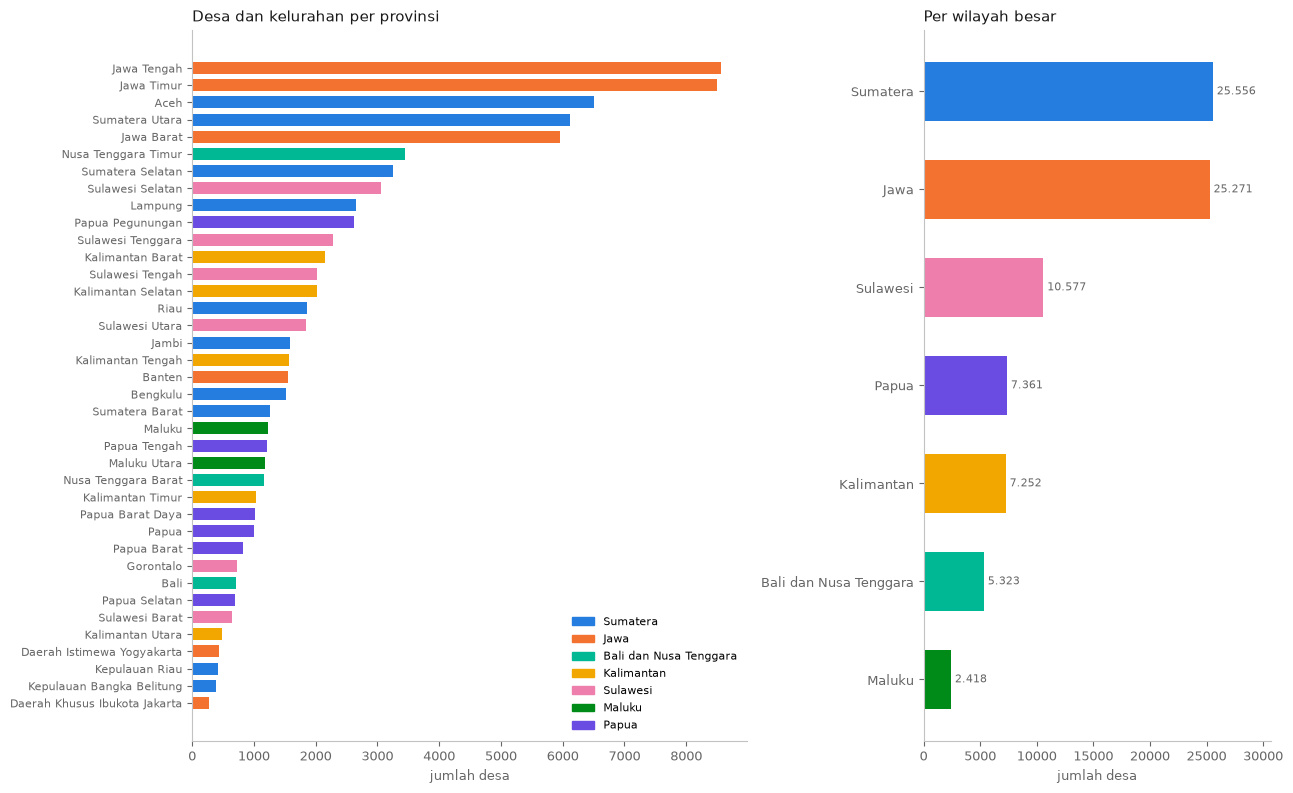

Terbanyak: Jawa Tengah (8563), tersedikit: Daerah Khusus Ibukota Jakarta (267), selisih 32 kali lipat


In [3]:
per_prov = df.groupby(["provinsi", "wilayah"]).size().rename("jumlah").reset_index().sort_values("jumlah")
per_wil = df["wilayah"].value_counts().reindex(URUT)

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [1.6, 1]})
a.barh(per_prov["provinsi"], per_prov["jumlah"], color=per_prov["wilayah"].map(WARNA), height=0.7)
a.set_title("Desa dan kelurahan per provinsi", loc="left")
a.set_xlabel("jumlah desa")
a.tick_params(axis="y", labelsize=8)
a.legend(handles=[Patch(color=WARNA[w], label=w) for w in URUT], loc="lower right", frameon=False, fontsize=8)

d = per_wil.sort_values()
b.barh(d.index, d.values, color=[WARNA[w] for w in d.index], height=0.6)
for y, v in enumerate(d.values):
    b.text(v, y, f" {v:,}".replace(",", "."), va="center", fontsize=8, color=TEKS2)
b.set_title("Per wilayah besar", loc="left")
b.set_xlabel("jumlah desa")
b.set_xlim(0, d.max() * 1.2)
plt.tight_layout()
plt.savefig(FIGS / "01_jumlah_desa.png", dpi=150)
plt.show()

terbanyak, tersedikit = per_prov.iloc[-1], per_prov.iloc[0]
print(f"Terbanyak: {terbanyak['provinsi']} ({terbanyak['jumlah']}), "
      f"tersedikit: {tersedikit['provinsi']} ({tersedikit['jumlah']}), "
      f"selisih {terbanyak['jumlah'] / tersedikit['jumlah']:.0f} kali lipat")

In [4]:
pd.crosstab(df["wilayah"], df["jenis"]).reindex(URUT)

jenis,desa,desa_adat,kelurahan
wilayah,,,
Sumatera,23184,0,2372
Jawa,22472,0,2799
Bali dan Nusa Tenggara,4793,0,530
Kalimantan,6638,0,614
Sulawesi,8755,0,1822
Maluku,2265,0,153
Papua,7142,14,205


## 2. Panjang nama desa

Panjang dihitung dua cara: jumlah huruf (tanpa spasi) dan jumlah kata.

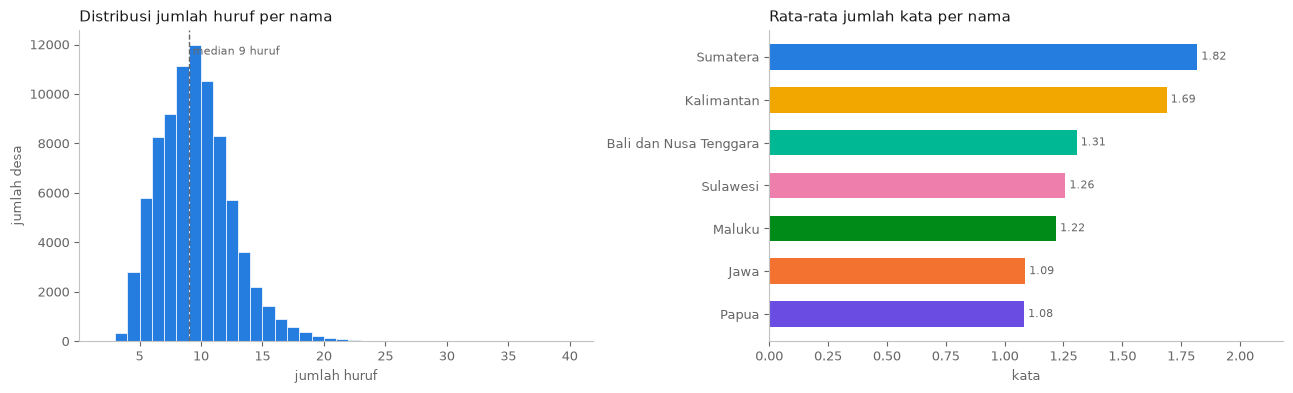

In [5]:
df["jumlah_huruf"] = df["nama_bersih"].str.replace(" ", "").str.len()
df["jumlah_kata"] = df["nama_bersih"].str.split().str.len()

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.hist(df["jumlah_huruf"], bins=range(2, 41), color=BIRU, edgecolor="white", linewidth=0.5)
a.axvline(df["jumlah_huruf"].median(), color=TEKS2, linestyle="--", linewidth=1)
a.text(df["jumlah_huruf"].median(), a.get_ylim()[1] * 0.92, f" median {df['jumlah_huruf'].median():.0f} huruf",
       color=TEKS2, fontsize=8)
a.set_title("Distribusi jumlah huruf per nama", loc="left")
a.set_xlabel("jumlah huruf")
a.set_ylabel("jumlah desa")

rata = df.groupby("wilayah")["jumlah_kata"].mean().reindex(URUT).sort_values()
b.barh(rata.index, rata.values, color=[WARNA[w] for w in rata.index], height=0.6)
for y, v in enumerate(rata.values):
    b.text(v, y, f" {v:.2f}", va="center", fontsize=8, color=TEKS2)
b.set_title("Rata-rata jumlah kata per nama", loc="left")
b.set_xlabel("kata")
b.set_xlim(0, rata.max() * 1.2)
plt.tight_layout()
plt.savefig(FIGS / "01_panjang_nama.png", dpi=150)
plt.show()

In [6]:
print("Sebaran jumlah kata:", df["jumlah_kata"].value_counts().sort_index().to_dict())
terpanjang = df.loc[df["jumlah_huruf"].idxmax()]
print(f"Nama terpanjang: {terpanjang['nama_asli']} ({terpanjang['kabupaten']}, {terpanjang['provinsi']}), "
      f"{terpanjang['jumlah_huruf']} huruf")
df.groupby("wilayah")[["jumlah_huruf", "jumlah_kata"]].median().reindex(URUT)

Sebaran jumlah kata: {1: 53436, 2: 27239, 3: 2878, 4: 185, 5: 18, 6: 2}
Nama terpanjang: Kampuang Tanjuang Koto Mambang Sungai Durian (Kabupaten Padang Pariaman, Sumatera Barat), 39 huruf


,jumlah_huruf,jumlah_kata
wilayah,,
Sumatera,10.0,2.0
Jawa,9.0,1.0
Bali dan Nusa Tenggara,8.0,1.0
Kalimantan,10.0,2.0
Sulawesi,8.0,1.0
Maluku,7.0,1.0
Papua,7.0,1.0


## 3. Nama paling sering dan nama kembar

Satu nama bisa dipakai banyak desa, bahkan di banyak provinsi. Untuk klasifikasi, ini berarti nama yang sama bisa punya label berbeda, dan juga alasan kenapa data latih dan uji di notebook 02 dipisah **per nama unik**.

62769 nama unik. 54868 dipakai satu desa saja, 4250 dipakai di lebih dari satu provinsi (mencakup 19771 desa).


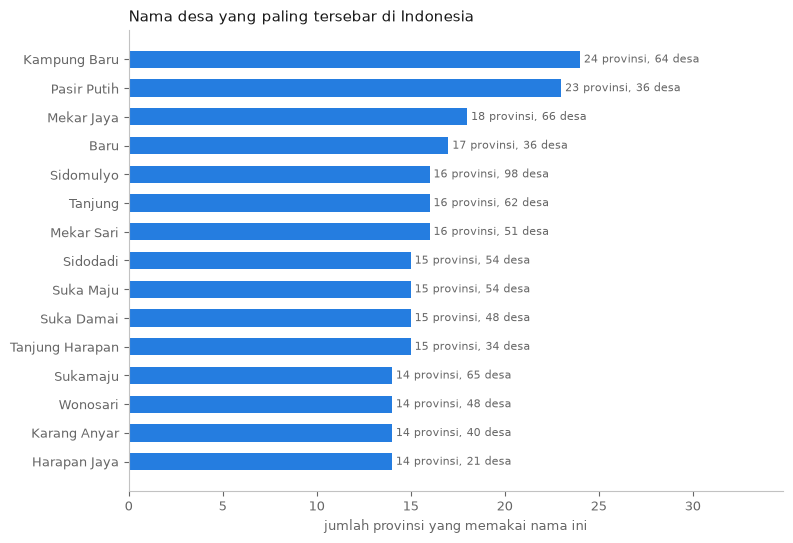

In [7]:
sebaran = (df.groupby("nama_bersih")
           .agg(jumlah_desa=("kode_desa", "size"), jumlah_provinsi=("provinsi", "nunique"))
           .sort_values(["jumlah_provinsi", "jumlah_desa"], ascending=False))
kembar = sebaran[sebaran["jumlah_provinsi"] > 1]
print(f"{len(sebaran)} nama unik. {(sebaran['jumlah_desa'] == 1).sum()} dipakai satu desa saja, "
      f"{len(kembar)} dipakai di lebih dari satu provinsi (mencakup {kembar['jumlah_desa'].sum()} desa).")

top = sebaran.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index.str.title(), top["jumlah_provinsi"], color=BIRU, height=0.6)
for y, (p, n) in enumerate(zip(top["jumlah_provinsi"], top["jumlah_desa"])):
    ax.text(p, y, f" {p} provinsi, {n} desa", va="center", fontsize=8, color=TEKS2)
ax.set_xlim(0, top["jumlah_provinsi"].max() * 1.45)
ax.set_xlabel("jumlah provinsi yang memakai nama ini")
ax.set_title("Nama desa yang paling tersebar di Indonesia", loc="left")
plt.tight_layout()
plt.savefig(FIGS / "01_nama_kembar.png", dpi=150)
plt.show()

In [8]:
df["nama_bersih"].value_counts().head(10).rename("jumlah_desa").to_frame()

,jumlah_desa
nama_bersih,
sidomulyo,98
sidorejo,71
karanganyar,70
mekar jaya,66
sukamaju,65
mekarsari,65
kampung baru,64
tanjung,62
sukorejo,60


## 4. Kata pertama dan akhiran paling umum per wilayah

Gambaran awal sebelum pemodelan: apakah tiap wilayah punya kata atau potongan huruf khas? Kata pertama sering berupa unsur geografi atau unsur bahasa daerah.

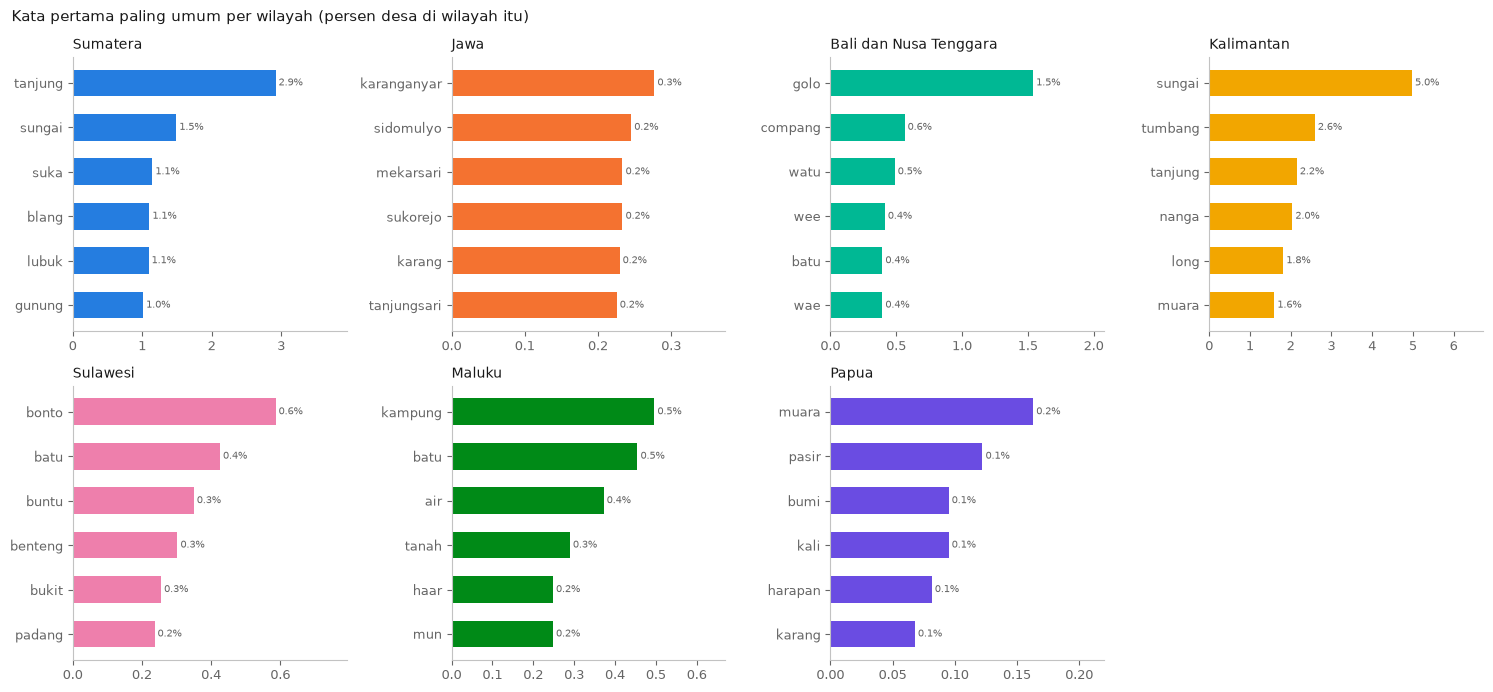

In [9]:
kata1 = df["nama_bersih"].str.split().str[0]
akhiran = df["nama_bersih"].str.split().str[-1].str[-3:]

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, w in zip(axes.ravel(), URUT):
    d = (kata1[df["wilayah"] == w].value_counts(normalize=True).head(6) * 100).iloc[::-1]
    ax.barh(d.index, d.values, color=WARNA[w], height=0.6)
    for y, v in enumerate(d.values):
        ax.text(v, y, f" {v:.1f}%", va="center", fontsize=7, color=TEKS2)
    ax.set_xlim(0, d.max() * 1.35)
    ax.set_title(w, loc="left", fontsize=10)
axes.ravel()[-1].axis("off")
fig.suptitle("Kata pertama paling umum per wilayah (persen desa di wilayah itu)", x=0.01, ha="left",
             fontsize=11, color=TEKS)
plt.tight_layout()
plt.savefig(FIGS / "01_kata_pertama.png", dpi=150)
plt.show()

In [10]:
tabel = {}
for w in URUT:
    m = df["wilayah"] == w
    tabel[w] = {
        "5 kata pertama teratas": ", ".join(kata1[m].value_counts().index[:5]),
        "5 akhiran 3 huruf teratas": ", ".join("-" + a for a in akhiran[m].value_counts().index[:5]),
    }
pd.DataFrame(tabel).T

,5 kata pertama teratas,5 akhiran 3 huruf teratas
Sumatera,"tanjung, sungai, suka, blang, lubuk","-ang, -aya, -ung, -aru, -ong"
Jawa,"karanganyar, sidomulyo, mekarsari, sukorejo, k...","-ari, -ang, -ejo, -ung, -gan"
Bali dan Nusa Tenggara,"golo, compang, watu, wee, batu","-ang, -ara, -ung, -ong, -tan"
Kalimantan,"sungai, tumbang, tanjung, nanga, long","-ang, -aya, -ung, -aru, -ulu"
Sulawesi,"bonto, batu, buntu, benteng, bukit","-ang, -aya, -ara, -atu, -eng"
Maluku,"kampung, batu, air, tanah, haar","-ang, -aya, -aru, -ara, -ing"
Papua,"muara, pasir, bumi, kali, harapan","-ama, -ari, -aga, -aya, -eri"


## 5. Ringkasan temuan

1. Data berisi 83.758 desa dan kelurahan dari 38 provinsi dan 514 kabupaten/kota, tanpa nilai kosong.
2. Jumlah desa sangat timpang: Jawa Tengah (8.563) dan Jawa Timur (8.494) punya lebih dari 30 kali lipat jumlah desa DKI Jakarta (267). Sumatera dan Jawa sendiri mencakup sekitar 60 persen data. Karena itu evaluasi memakai macro-F1 dan model memakai bobot kelas seimbang.
3. Nama desa umumnya pendek: median 9 huruf, dan 64 persen hanya satu kata. Nama di Sumatera dan Kalimantan rata-rata lebih panjang (sekitar 1,7 sampai 1,8 kata) karena banyak memakai unsur geografi di depan, seperti "Sungai", "Tanjung", dan "Lubuk". Nama di Jawa dan Papua hampir selalu satu kata.
4. Nama terpanjang adalah "Kampuang Tanjuang Koto Mambang Sungai Durian" di Sumatera Barat.
5. Dari 62.769 nama unik, 54.868 hanya dipakai satu desa. Tetapi 4.250 nama dipakai di lebih dari satu provinsi. Yang paling tersebar adalah nama generik berbahasa Indonesia: "Kampung Baru" (24 provinsi), "Pasir Putih" (23), dan "Mekar Jaya" (18). Nama Jawa seperti "Sidomulyo" (98 desa, 16 provinsi) juga tersebar luas, petunjuk awal jejak transmigrasi yang dianalisis di notebook 04.
6. Kata pertama yang paling umum langsung memperlihatkan ciri wilayah: "sungai", "tumbang", "nanga", dan "long" di Kalimantan; "tanjung", "blang", dan "lubuk" di Sumatera; "bonto" dan "buntu" di Sulawesi; "golo" dan "compang" di Nusa Tenggara. Di Jawa polanya lain: kata pertama tersering hanya mencakup 0,3 persen desa, karena nama Jawa biasanya satu kata gabungan ("Karanganyar", "Sidomulyo") sehingga lebih beragam. Ciri khasnya ada di dalam kata, bukan di kata depan.
7. Akhiran "-ang" umum di hampir semua wilayah, jadi tidak khas. Sebaliknya, dari 1.510 nama berakhiran "-ejo", 81 persen ada di Jawa dan 16 persen di Sumatera (kemungkinan besar desa transmigrasi). Artinya potongan huruf memang membawa informasi daerah, tetapi perlu model yang menimbang banyak potongan sekaligus, bukan satu aturan saja.